In [1]:
# =============================================================================
# CELDA 1 · Dependencias y configuración
# Objetivo: traer todo lo necesario para EXPERIMENTAR: datos, modelos,
# métricas y tracking. Esta celda no entrena nada, solo prepara el entorno.
# =============================================================================
import pandas as pd
import numpy as np
import joblib                      # serializar modelos/preprocesadores a disco (.pkl)
import mlflow                      # tracking de experimentos: parámetros, métricas, artefactos
import mlflow.sklearn              # "flavor" de MLflow para guardar modelos de scikit-learn

# train_test_split: separa datos de entrenamiento y de prueba.
# GridSearchCV: búsqueda exhaustiva de hiperparámetros con validación cruzada.
from sklearn.model_selection import train_test_split, GridSearchCV

# Familia "árboles y ensambles": capturan relaciones NO lineales e interacciones
# entre features (p. ej. zona x área) sin necesidad de escalar los datos.
#   - RandomForest: bagging (muchos árboles en paralelo, promedio).
#   - GradientBoosting: boosting (cada árbol corrige el error del anterior).
#   - HistGradientBoosting: boosting por histogramas, mucho más rápido en datasets grandes.
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

# Familia "lineal": es el BASELINE. Si un modelo complejo no supera a la
# regresión lineal, la complejidad extra no se justifica.
from sklearn.linear_model import LinearRegression

# Métricas de REGRESIÓN (el target 'price' es un número, no una clase):
#   MAE  -> error promedio en la misma unidad del precio, fácil de explicar al negocio.
#   MSE  -> penaliza mucho los errores grandes (eleva al cuadrado).
#   R2   -> proporción de la varianza explicada; 1.0 es perfecto, 0 es "igual que predecir la media".
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import yaml                        # el resultado del experimento se guarda como config legible (YAML)
import os
import logging
from contextlib import nullcontext # permite correr el notebook SIN MLflow usando el mismo código
import matplotlib.pyplot as plt

# Logging en vez de print para los mensajes de proceso: en producción estos
# mensajes van a un archivo o a CloudWatch, no a la pantalla.
logging.basicConfig(level=logging.INFO)
logger = logging.getLogger()

# URI del servidor de MLflow. Si se deja vacío ('' o None) el notebook corre
# igual pero sin registrar nada: así el experimento no depende de que el servidor exista.
mlflow_tracking_uri = 'http://localhost:5555'  # Optional: e.g., 'http://localhost:5555'

## ¿Está corriendo MLflow?

El notebook registra parámetros, métricas y modelos en un **servidor de MLflow** (`mlflow_tracking_uri`). Si el servidor no está arriba, `mlflow.start_run()` falla con `ConnectionRefusedError`.

**Levantar el servidor (desde la raíz del repo):**

```bash
cd deployment/mlflow
docker compose -f docker-compose.yaml up -d   # Podman: podman compose -f docker-compose.yaml up -d
docker compose ps                             # debe mostrar mlflow-tracking-server "Up"
```

El contenedor expone el puerto `5000` interno como **`5555`** en tu máquina → UI en [http://localhost:5555](http://localhost:5555).

**Detener / ver logs:**

```bash
docker compose -f docker-compose.yaml logs -f mlflow
docker compose -f docker-compose.yaml down
```

**Alternativa sin Docker** (solo para pruebas rápidas, guarda todo en la carpeta actual):

```bash
mlflow server --host 127.0.0.1 --port 5555 --backend-store-uri sqlite:///mlflow.db
```

La celda siguiente verifica la conexión. Si el servidor no responde, pone `mlflow_tracking_uri = None` para que el resto del notebook corra **sin tracking** (los resultados se pierden al reiniciar el kernel).

In [2]:
# =============================================================================
# CELDA 1b · Verificar que el servidor de MLflow responde
# ¿Por qué validar antes de entrenar? GridSearch puede tardar varios minutos;
# si MLflow está caído, el error aparecería recién al registrar el primer run
# y se perdería todo ese tiempo de cómputo.
# =============================================================================
import urllib.request
import urllib.error

def check_mlflow(uri, timeout=3):
    """Devuelve True si el endpoint /health del servidor MLflow responde 'OK'."""
    if not uri:
        return False
    try:
        with urllib.request.urlopen(f"{uri.rstrip('/')}/health", timeout=timeout) as r:
            return r.status == 200 and r.read().decode().strip() == "OK"
    except (urllib.error.URLError, OSError, ValueError):
        return False

if check_mlflow(mlflow_tracking_uri):
    print(f"✅ MLflow server activo en {mlflow_tracking_uri}")
    print(f"   UI: {mlflow_tracking_uri}")
else:
    print(f"❌ No hay servidor MLflow en {mlflow_tracking_uri}")
    print("   Levántalo con:")
    print("     cd deployment/mlflow && docker compose -f docker-compose.yaml up -d")
    print("   y vuelve a ejecutar esta celda.")
    # Se desactiva el tracking para que el notebook siga funcionando sin registrar runs.
    mlflow_tracking_uri = None
    print("\n⚠️  Continuando SIN tracking (mlflow_tracking_uri = None).")

✅ MLflow server activo en http://127.0.0.1:5555
   UI: http://127.0.0.1:5555


In [3]:
# =============================================================================
# CELDA 2 · Carga del dataset ya procesado y split train/test
# Objetivo: partir de las features generadas en la etapa anterior del pipeline
# (feature engineering), no de los datos crudos. Cada etapa consume la salida
# de la anterior: eso es lo que hace reproducible el flujo.
# =============================================================================
# Load dataset
# Ejecutar el siguiente comando para generar el archivo: featured_house_data.csv
# python src/features/engineer.py   --input data/processed/cleaned_house_data.csv   --output data/processed/featured_house_data.csv   --preprocessor models/trained/preprocessor.pkl
data_path = '../data/processed/featured_house_data.csv'  # Update path if needed
data = pd.read_csv(data_path)

# ¿Por qué NO volver a hacer train_test_split aquí?
# engineer.py ya separó train/test ANTES de ajustar el preprocessor (imputación,
# one-hot) y marcó cada fila en la columna `split`. Si re-partimos al azar:
#   1. filas de "test" (que el preprocessor nunca vio) caerían en train y viceversa
#      -> data leakage sutil;
#   2. el holdout del notebook sería distinto al de src/models/train_model.py
#      -> las métricas del experimento y las del pipeline no serían comparables.
# Además `split` es texto ('train'/'test'): si se queda en X, sklearn falla con
# "could not convert string to float: 'train'".
if 'split' in data.columns:
    train_df = data[data['split'] == 'train']
    test_df = data[data['split'] == 'test']
    # X = todas las columnas menos el target y la marca de split; y = la variable a predecir.
    # 'price' es numérico y continuo -> problema de REGRESIÓN -> modelos y métricas de regresión.
    X = data.drop(columns=['price', 'split'])
    y = data['price']
    X_train, y_train = train_df.drop(columns=['price', 'split']), train_df['price']
    X_test, y_test = test_df.drop(columns=['price', 'split']), test_df['price']
    print("Holdout fijo tomado de la columna 'split' (misma partición que engineer.py / train_model.py)")
else:
    # Fallback para CSVs antiguos sin columna `split`:
    # 80 % entrenamiento / 20 % prueba. El test NUNCA se usa para elegir
    # hiperparámetros: solo para la evaluación final, así la métrica no queda "inflada".
    # random_state=42 fija la semilla: todos los modelos ven EXACTAMENTE el mismo split,
    # requisito para que la comparación entre modelos sea justa y repetible.
    X = data.drop('price', axis=1)
    y = data['price']
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
    print("Sin columna 'split': se usó train_test_split(test_size=0.2, random_state=42)")

print(f"X_train: {X_train.shape}  X_test: {X_test.shape}  features: {list(X.columns)[:5]}...")

Holdout fijo tomado de la columna 'split' (misma partición que engineer.py / train_model.py)
X_train: (61, 15)  X_test: (16, 15)  features: ['num__sqft', 'num__bedrooms', 'num__bathrooms', 'num__house_age', 'num__bed_bath_ratio']...


In [4]:
# =============================================================================
# CELDA 3 · Selección de features con RFE (Recursive Feature Elimination)
# ¿Por qué seleccionar features?
#   - Menos columnas = modelos más simples, más rápidos de entrenar y de servir.
#   - Reduce el ruido y el riesgo de overfitting.
#   - Menos dependencias en producción: cada feature es un dato que hay que
#     calcular, validar y monitorear (drift). Menos piezas, menos fallas.
# ¿Por qué RFE y no solo "correlación con el target"?
#   - La correlación mira cada feature por separado y solo relaciones lineales.
#   - RFE entrena un modelo, elimina la feature menos importante, reentrena y
#     repite hasta quedarse con N: evalúa las features EN CONJUNTO y captura
#     interacciones y no linealidades.
# ¿Por qué RandomForest como estimador dentro de RFE?
#   - Expone feature_importances_, requisito de RFE.
#   - Es robusto: no necesita escalar datos y no se desestabiliza con outliers.
#   - No agrega dependencias externas (vs. XGBoost/LightGBM) y es la misma
#     familia que luego competirá en el experimento.
# =============================================================================
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor

# Use RandomForest for RFE (más estable y sin dependencias externas)
# n_estimators=100 es suficiente para importancias estables; random_state fija el resultado.
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# RFE with RandomForest
# n_features_to_select=10 es una decisión de diseño: equilibrio entre poder
# predictivo y simplicidad. Es un hiperparámetro más: se podría validar
# probando 8, 10, 15 y comparando el R2 resultante.
rfe_selector = RFE(estimator=rf_model, n_features_to_select=10)
rfe_selector.fit(X_train, y_train)          # solo con TRAIN: el test no participa en ninguna decisión
rfe_selected_features = X.columns[rfe_selector.support_]   # support_ = máscara booleana de las elegidas
rfe_ignored_features = X.columns[~rfe_selector.support_]

print("✅ Top 10 Selected Features by RFE (using RandomForest):")
for feature in rfe_selected_features:
    print(f" - {feature}")

print("\n❌ Features Ignored by RFE:")
for feature in rfe_ignored_features:
    print(f" - {feature}")

# Store for config
# Se guarda la lista de features elegidas porque el pipeline de entrenamiento
# (src/models/train.py) y el de inferencia deben usar EXACTAMENTE las mismas
# columnas. Si no se persiste, el modelo en producción recibe otras features.
selected_features_dict = {
    'rfe': list(rfe_selected_features),
    'rfe_method': 'RandomForestRegressor',
    'total_features': len(X.columns),
    'selected_features_count': len(rfe_selected_features)
}

print(f"\n📊 Feature Selection Summary:")
print(f"   Original features: {len(X.columns)}")
print(f"   Selected features: {len(rfe_selected_features)}")
print(f"   Reduction: {len(X.columns) - len(rfe_selected_features)} features removed")

# Filter datasets to use only selected features for experimentation
# A partir de aquí TODOS los modelos compiten con las mismas 10 features:
# otra condición para que la comparación sea justa.
X_train = X_train[rfe_selected_features]
X_test = X_test[rfe_selected_features]

print(f"\n✅ Datasets filtered to use only selected features")
print(f"   X_train shape: {X_train.shape}")
print(f"   X_test shape: {X_test.shape}")

✅ Top 10 Selected Features by RFE (using RandomForest):
 - num__sqft
 - num__bedrooms
 - num__bathrooms
 - num__house_age
 - num__bed_bath_ratio
 - cat__location_Downtown
 - cat__location_Rural
 - cat__location_Suburb
 - cat__location_Waterfront
 - cat__condition_Good

❌ Features Ignored by RFE:
 - cat__location_Mountain
 - cat__location_Urban
 - cat__condition_Excellent
 - cat__condition_Fair
 - cat__condition_Poor

📊 Feature Selection Summary:
   Original features: 15
   Selected features: 10
   Reduction: 5 features removed

✅ Datasets filtered to use only selected features
   X_train shape: (61, 10)
   X_test shape: (16, 10)


In [5]:
# =============================================================================
# CELDA 4 · Configuración del experimento en MLflow
# ¿Por qué MLflow?
#   Sin tracking, los resultados viven en la memoria del notebook y se pierden
#   al reiniciar el kernel. MLflow registra parámetros, métricas y el modelo
#   de CADA corrida: permite comparar, reproducir y auditar (principio MLOps
#   de trazabilidad).
# Un "experimento" agrupa varias corridas (runs) del mismo problema.
# =============================================================================
# Optional MLflow setup
# mlflow blocks reusing a name that belongs to a soft-deleted experiment, so
# we restore it first; if restore isn't possible we fall back to a new name.
experiment_name = "House Price Prediction Experiment"

if mlflow_tracking_uri:                       # todo el bloque es opcional: sin URI no hay tracking
    mlflow.set_tracking_uri(mlflow_tracking_uri)
    client = mlflow.tracking.MlflowClient()   # cliente de bajo nivel para consultar/crear experimentos
    experiment = client.get_experiment_by_name(experiment_name)

    if experiment is None:
        # Primera vez: se crea el experimento.
        client.create_experiment(experiment_name)
        logger.info(f"Created new MLflow experiment: {experiment_name}")
    elif experiment.lifecycle_stage == "deleted":
        # MLflow hace "soft delete": el nombre queda reservado y set_experiment
        # fallaría. Se intenta restaurar; si no se puede, se usa otro nombre.
        try:
            client.restore_experiment(experiment.experiment_id)
            logger.warning(f"Restored soft-deleted experiment: {experiment_name}")
        except Exception:
            experiment_name = f"{experiment_name} (recreated)"
            client.create_experiment(experiment_name)
            logger.warning(
                f"Could not restore deleted experiment; created '{experiment_name}' instead."
            )

    # Desde aquí, cada mlflow.start_run() quedará asociado a este experimento.
    mlflow.set_experiment(experiment_name)

In [6]:
# =============================================================================
# CELDA 5 · Candidatos y espacio de búsqueda de hiperparámetros
# ¿Por qué estos 4 modelos y no otros?
#   El problema es de REGRESIÓN sobre datos TABULARES. Para tablas, las
#   familias que mejor suelen funcionar son la lineal (baseline) y los
#   árboles/ensambles. Redes neuronales o SVR quedan fuera: más costo y
#   normalmente no ganan en datasets tabulares de este tamaño.
#   Se cubre una "escalera" de complejidad:
#     LinearRegression  -> baseline, sin hiperparámetros, referencia mínima.
#     RandomForest      -> bagging: árboles independientes, robusto, poco tuning.
#     GradientBoosting  -> boosting: suele bajar el error, pero es más sensible al tuning.
#     HistGradientBoosting -> boosting por histogramas: rápido, regularización L2, nulos nativos.
# =============================================================================
# Define models and hyperparameter grids
models = {
    'LinearRegression': LinearRegression(),
    'RandomForest': RandomForestRegressor(),
    'GradientBoosting': GradientBoostingRegressor(),
    'HistGradientBoosting': HistGradientBoostingRegressor()
}

# Grillas de hiperparámetros: GridSearchCV probará TODAS las combinaciones.
# Ojo con el costo: RandomForest = 5*6*3*3 = 270 combinaciones x 3 folds = 810 entrenamientos.
# Con grillas más grandes conviene RandomizedSearchCV u Optuna.
model_grids = {
    # Sin hiperparámetros: la regresión lineal "ordinaria" no tiene nada que tunear.
    'LinearRegression': {},

    'RandomForest': {
        'n_estimators': [50, 100, 150, 200, 300],      # nº de árboles: más = más estable, más lento
        'max_depth': [None, 5, 10, 15, 20, 25],        # profundidad: None = crece hasta hojas puras (riesgo de overfitting)
        'min_samples_split': [2, 5, 10],               # mínimo de muestras para dividir un nodo (regulariza)
        'min_samples_leaf': [1, 2, 4]                  # mínimo de muestras por hoja (regulariza)
    },

    'GradientBoosting': {
        'n_estimators': [50, 100, 150, 200, 300],      # nº de etapas de boosting
        'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2], # cuánto aporta cada árbol; bajo = más árboles necesarios
        'max_depth': [3, 5, 7, 10],                    # en boosting se usan árboles cortos (3-7 es típico)
        'subsample': [0.8, 0.9, 1.0]                   # <1.0 = stochastic gradient boosting, reduce varianza
    },

    'HistGradientBoosting': {
        'max_iter': [50, 100, 150, 200, 300],          # equivalente a n_estimators
        'learning_rate': [0.01, 0.05, 0.1, 0.15, 0.2],
        'max_depth': [3, 5, 7, 10, None],
        'l2_regularization': [0.0, 0.1, 0.5, 1.0]      # penalización L2 sobre las hojas: controla overfitting
    }
}

In [7]:
# =============================================================================
# CELDA 6 · Función de evaluación: tuning + métricas en test
# ¿Por qué una función? Para que los 4 modelos pasen por EXACTAMENTE el mismo
# procedimiento. Si cada uno se evaluara "a mano", la comparación no sería válida.
# =============================================================================
def evaluate_model_with_gridsearch(name, model, grid, X_train, y_train, X_test, y_test):
    if grid:
        # GridSearchCV:
        #   cv=3        -> validación cruzada de 3 folds SOBRE TRAIN. El test no se toca.
        #                  3 (y no 5 o 10) para limitar el costo de las grillas grandes.
        #   scoring='r2'-> criterio para elegir la mejor combinación; debe ser la MISMA
        #                  métrica con la que luego se elige el mejor modelo (celda 9).
        #   n_jobs=-1   -> usa todos los núcleos de CPU en paralelo.
        clf = GridSearchCV(model, grid, cv=3, scoring='r2', n_jobs=-1)
        clf.fit(X_train, y_train)
        best_model = clf.best_estimator_      # ya reentrenado con todo el train usando los mejores params
        best_params = clf.best_params_
    else:
        # Caso sin grilla (LinearRegression): se entrena directo.
        model.fit(X_train, y_train)
        best_model = model
        best_params = model.get_params()

    # Evaluación final en TEST: datos que el modelo nunca vio, ni en el tuning.
    y_pred = best_model.predict(X_test)
    mae = mean_absolute_error(y_test, y_pred)   # error promedio en unidades de precio
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)                          # raíz del MSE: vuelve a unidades de precio, castiga errores grandes
    r2 = r2_score(y_test, y_pred)                # varianza explicada (0-1); se usa para rankear modelos

    # Se devuelve todo junto: métricas para comparar, modelo y params para registrar.
    return {
        'mae': mae,
        'mse': mse,
        'rmse': rmse,
        'r2': r2,
        'model': best_model,
        'params': best_params
    }

print("MLflow tracking URI:", mlflow_tracking_uri)

MLflow tracking URI: http://127.0.0.1:5555


In [8]:
# =============================================================================
# CELDA 7 · Ejecución del experimento: entrenar, evaluar y registrar cada modelo
# Estructura en MLflow:
#   run padre  "model_comparison"  -> agrupa toda la comparación
#     └ run hijo por modelo (nested=True) -> params, métricas y artefacto de ESE modelo
# Así en la UI de MLflow se comparan los 4 hijos lado a lado.
# =============================================================================
results = {}

# Si no hay tracking URI, nullcontext() hace que el "with" no haga nada:
# el mismo código corre con o sin MLflow.
with mlflow.start_run(run_name="model_comparison") if mlflow_tracking_uri else nullcontext():
    for name, model in models.items():
        logger.info(f"Training {name}...")
        with mlflow.start_run(run_name=name, nested=True) if mlflow_tracking_uri else nullcontext():
            # Mismo split, mismas features, misma función: comparación justa.
            evaluation = evaluate_model_with_gridsearch(name, model, model_grids[name], X_train, y_train, X_test, y_test)
            results[name] = evaluation

            if mlflow_tracking_uri:
                # Parámetros: para saber CON QUÉ configuración se obtuvo el resultado.
                mlflow.log_params(evaluation['params'])
                # Métricas: para comparar corridas y detectar degradación en el futuro.
                mlflow.log_metrics({
                    'mae': evaluation['mae'],
                    'mse': evaluation['mse'],
                    'rmse': evaluation['rmse'],
                    'r2': evaluation['r2']
                })
                # Artefacto: el modelo entrenado queda guardado y versionado;
                # desde aquí se puede registrar en el Model Registry y desplegar.
                mlflow.sklearn.log_model(evaluation['model'], artifact_path=name.lower().replace(" ", "_"))

            print(f"{name} R2: {evaluation['r2']:.4f}, RMSE: {evaluation['rmse']:.2f}")

INFO:root:Training LinearRegression...


2026/11/06 22:11:29 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/06 22:11:29 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


LinearRegression R2: 0.9471, RMSE: 49621.82
🏃 View run LinearRegression at: http://127.0.0.1:5555/#/experiments/1/runs/43437100e33748c0912d4878e17a7d68
🧪 View experiment at: http://127.0.0.1:5555/#/experiments/1


INFO:root:Training RandomForest...


2026/11/06 22:16:10 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


... (7 outputs left out)

🏃 View run GradientBoosting at: http://127.0.0.1:5555/#/experiments/1/runs/624a6fc2dba64ba48027df4591190808
🧪 View experiment at: http://127.0.0.1:5555/#/experiments/1


2026/11/06 22:21:12 WARNING mlflow.utils.environment: Failed to resolve installed pip version. ``pip`` will be added to conda.yaml environment spec without a version specifier.


2026/11/06 22:21:12 WARNING mlflow.models.model: Model logged without a signature and input example. Please set `input_example` parameter when logging the model to auto infer the model signature.


HistGradientBoosting R2: 0.8176, RMSE: 92167.41
🏃 View run HistGradientBoosting at: http://127.0.0.1:5555/#/experiments/1/runs/beb16f8563504792b5b665c067fa6cc4
🧪 View experiment at: http://127.0.0.1:5555/#/experiments/1
🏃 View run model_comparison at: http://127.0.0.1:5555/#/experiments/1/runs/ed0b8858c27944dd83e8749ba4b592ea
🧪 View experiment at: http://127.0.0.1:5555/#/experiments/1


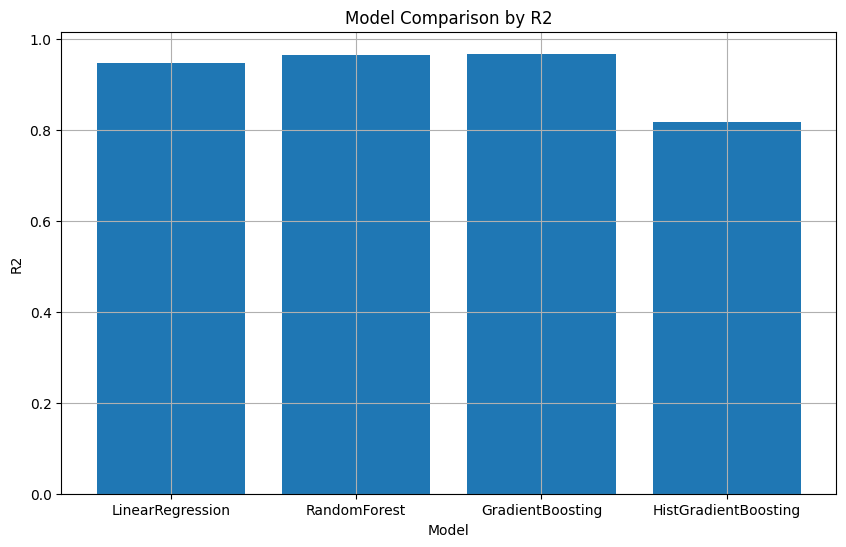

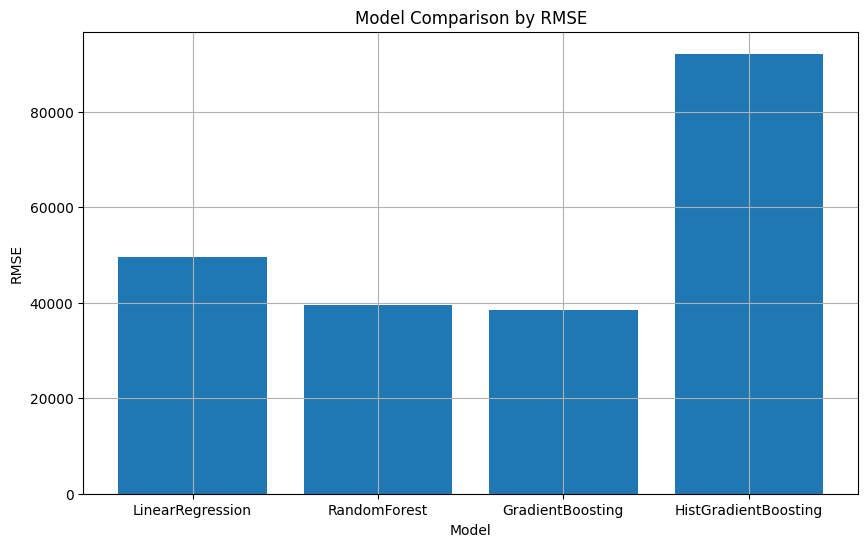

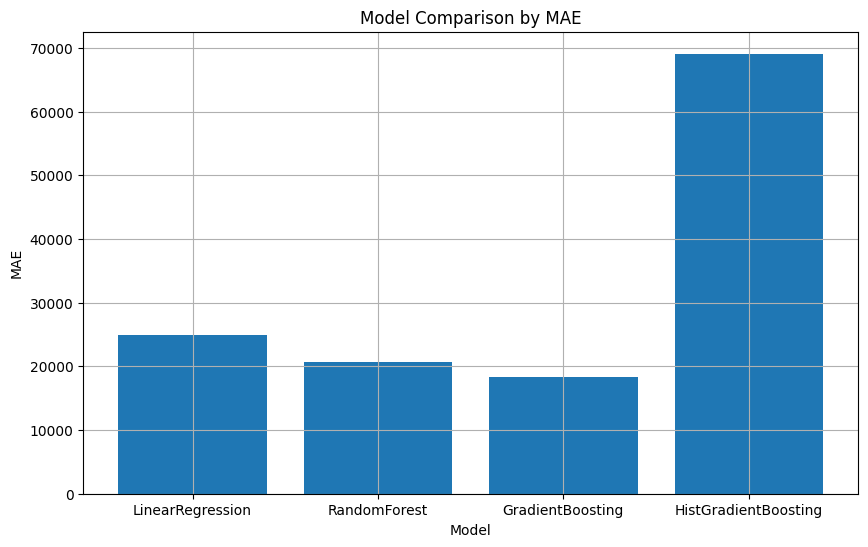

In [9]:
# =============================================================================
# CELDA 8 · Visualización comparativa
# ¿Por qué graficar si ya tenemos los números? Para ver de un vistazo si la
# diferencia entre modelos es grande o marginal. Si dos modelos empatan en R2,
# conviene elegir el más simple/barato de servir, no el "más sofisticado".
# =============================================================================
def plot_model_metrics(results, metric='r2'):
    names = list(results.keys())
    values = [results[name][metric] for name in names]

    plt.figure(figsize=(10, 6))
    plt.bar(names, values)
    plt.title(f'Model Comparison by {metric.upper()}')
    plt.xlabel('Model')
    plt.ylabel(metric.upper())
    plt.grid(True)
    plt.show()

# Example usage:
# Se miran las 3 métricas porque cuentan cosas distintas:
#   r2   -> cuánta varianza explica (más alto = mejor)
#   rmse -> error típico castigando errores grandes (más bajo = mejor)
#   mae  -> error promedio "honesto" en unidades de precio (más bajo = mejor)
# Si un modelo gana en R2 pero pierde en MAE, hay que decidir según el negocio.
plot_model_metrics(results, metric='r2')
plot_model_metrics(results, metric='rmse')
plot_model_metrics(results, metric='mae')

In [10]:
# =============================================================================
# CELDA 9 · Selección del mejor modelo y persistencia de la configuración
# ¿Por qué guardar un YAML y no solo "recordar" el ganador?
#   El experimento termina aquí, pero el pipeline sigue: src/models/train.py
#   lee este archivo para reentrenar el modelo ganador con sus hiperparámetros
#   y las features seleccionadas. La decisión queda versionada en Git junto
#   al código: cualquiera puede reproducirla.
# =============================================================================
import yaml

# Save model config with selected features
# Display information about the best model
# Criterio de selección: mayor R2 en test. Debe ser el MISMO criterio usado en
# GridSearchCV (scoring='r2') para ser coherentes de principio a fin.
best_model_name = max(results, key=lambda x: results[x]['r2'])
best_model = results[best_model_name]['model']
best_params = best_model.get_params()
# float(): las métricas vienen como numpy.float64 y YAML no las serializa bien.
best_r2 = float(results[best_model_name]['r2'])
best_mae = float(results[best_model_name]['mae'])
best_rmse = float(results[best_model_name]['rmse'])

print(f"🏆 Best Model: {best_model_name}")
print(f"   R² Score: {best_r2:.4f}")
print(f"   MAE: {best_mae:.2f}")
print(f"   RMSE: {best_rmse:.2f}")

# Contrato entre experimentación y entrenamiento: nombre del modelo ganador,
# sus hiperparámetros, las métricas de referencia y las features a usar.
model_config = {
    'model': {
        'name': 'house_price_model',
        'best_model': best_model_name,
        'parameters': best_params,
        'r2_score': best_r2,                 # métrica de referencia: si el reentrenamiento da menos, algo cambió
        'mae': best_mae,
        'target_variable': 'price',
        'feature_sets': selected_features_dict,  # las 10 features de RFE (celda 3)
        # Umbrales de calidad que train_model.py exige en el holdout. Si no se cumplen,
        # el script termina con exit 1 y el pipeline de CI no publica la imagen Docker.
        'quality_gate': {
            'min_r2': 0.90,              # R² mínimo
            'max_mape': 0.10,            # error porcentual máximo (10 %)
            'must_beat_baseline': True   # MAE menor que predecir siempre la mediana
        }
    }
}

config_path = '../configs/model_config.yaml'
os.makedirs(os.path.dirname(config_path), exist_ok=True)
with open(config_path, 'w') as f:
    yaml.dump(model_config, f)

print(f"Saved model config to {config_path}")

🏆 Best Model: GradientBoosting
   R² Score: 0.9682
   MAE: 18346.64
   RMSE: 38515.07
Saved model config to ../configs/model_config.yaml
